# Nested versus non-nested cross-validation: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/model_selection/plot_nested_cross_validation_iris.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/model_selection/plot_nested_cross_validation_iris.html)).

**Scenario:** an RBF `SVC` is tuned over `{"C": [1, 10, 100], "gamma": [0.01, 0.1]}` on iris in 30 trials.
Each trial uses `KFold(n_splits=4, shuffle=True, random_state=i)` for both loops: `GridSearchCV(cv=outer_cv)`
gives the non-nested `best_score_`; `cross_val_score(GridSearchCV(cv=inner_cv), cv=outer_cv)` gives the nested score.

**Adaptations:**
- Moxie needs an explicit typed `SearchAdapter` (row slicing, parameter application, default scorer/CV): the
  documented typed-interface difference. Grid values are Float64; `gamma` goes through `moxie.svm.Gamma`.
- `GridSearchCV.cv` takes a materialized fold list. In the nested loop the inner folds must be recomputed on
  each outer training subset, so the adapter's `default_cv` applies `KFold(4, shuffle=True, random_state=i)` to
  whatever rows it receives — exactly what sklearn's `inner_cv.split(X_train)` does.
- **Defect (GAP below):** `cross_val_score` cannot take a `GridSearchCV` as its estimator on Mojo 1.0: the search
  structs carry struct-level `where` clauses, and the compiler rejects every function parameter typed with such a
  struct ("cannot implicitly convert 'GridSearchCV[…]' value to 'GridSearchCV[…]'"; inside `cross_validate` it
  crashes the compiler). The Moxie cell therefore writes `cross_val_score` out: one unfitted `clone` of the search per
  outer fold, `fit` on the outer training rows, `score` on the outer test rows — the reference's semantics.
- Extra checks beyond the example: all `cv_results_` split/mean/rank values, `return_train_score`, the refitted
  `predict`/`decision_function`/`support_` delegated through `best_estimator_`, and a seeded `RandomizedSearchCV`.

**Determinism:** fully deterministic (fixed fold seeds, deterministic libsvm-style SMO), so scores, ranks,
indices and predictions must match exactly; `decision_function` allows a small floating tolerance.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("model_selection/plot_nested_cross_validation_iris")

## 1. scikit-learn (Python reference)

The example code, unchanged except for a smaller figure.

In [2]:
import numpy as np
from matplotlib import pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score
from sklearn.svm import SVC

plt.rcParams["figure.dpi"] = 60

# Number of random trials
NUM_TRIALS = 30

# Load the dataset
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

# Set up possible values of parameters to optimize over
p_grid = {"C": [1, 10, 100], "gamma": [0.01, 0.1]}

# We will use a Support Vector Classifier with "rbf" kernel
svm = SVC(kernel="rbf")

# Arrays to store scores
non_nested_scores = np.zeros(NUM_TRIALS)
nested_scores = np.zeros(NUM_TRIALS)

# Loop for each trial
for i in range(NUM_TRIALS):
    # Choose cross-validation techniques for the inner and outer loops,
    # independently of the dataset.
    # E.g "GroupKFold", "LeaveOneOut", "LeaveOneGroupOut", etc.
    inner_cv = KFold(n_splits=4, shuffle=True, random_state=i)
    outer_cv = KFold(n_splits=4, shuffle=True, random_state=i)

    # Non_nested parameter search and scoring
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=outer_cv)
    clf.fit(X_iris, y_iris)
    non_nested_scores[i] = clf.best_score_

    # Nested CV with parameter optimization
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=inner_cv)
    nested_score = cross_val_score(clf, X=X_iris, y=y_iris, cv=outer_cv)
    nested_scores[i] = nested_score.mean()

score_difference = non_nested_scores - nested_scores

print(
    "Average difference of {:6f} with std. dev. of {:6f}.".format(
        score_difference.mean(), score_difference.std()
    )
)

Average difference of 0.007581 with std. dev. of 0.007833.


In [3]:
# Extra reference values compared below (same objects, more attributes).
from sklearn.model_selection import RandomizedSearchCV

sk = {"best_index": [], "mean_test_score": [], "rank_test_score": [], "split_test_scores": [], "nested_folds": []}
for i in range(NUM_TRIALS):
    outer_cv = KFold(n_splits=4, shuffle=True, random_state=i)
    clf = GridSearchCV(estimator=svm, param_grid=p_grid, cv=outer_cv).fit(X_iris, y_iris)
    sk["best_index"].append(clf.best_index_)
    sk["mean_test_score"] += list(clf.cv_results_["mean_test_score"])
    sk["rank_test_score"] += list(clf.cv_results_["rank_test_score"])
    for c in range(len(clf.cv_results_["params"])):
        sk["split_test_scores"] += [clf.cv_results_[f"split{f}_test_score"][c] for f in range(4)]
    inner = GridSearchCV(estimator=svm, param_grid=p_grid, cv=KFold(n_splits=4, shuffle=True, random_state=i))
    sk["nested_folds"] += list(cross_val_score(inner, X=X_iris, y=y_iris, cv=outer_cv))
first = GridSearchCV(svm, p_grid, cv=KFold(4, shuffle=True, random_state=0), return_train_score=True).fit(X_iris, y_iris)
random = RandomizedSearchCV(svm, p_grid, n_iter=4, random_state=0, cv=KFold(4, shuffle=True, random_state=0)).fit(X_iris, y_iris)
print("cv_results_ keys:", sorted(first.cv_results_))
print("trial-0 best_params_:", first.best_params_, "randomized params:", random.cv_results_["params"])
nb.share(X_iris=X_iris, y_iris=y_iris.astype(np.int64), num_trials=np.array([NUM_TRIALS, 0]))

cv_results_ keys: ['mean_fit_time', 'mean_score_time', 'mean_test_score', 'mean_train_score', 'param_C', 'param_gamma', 'params', 'rank_test_score', 'split0_test_score', 'split0_train_score', 'split1_test_score', 'split1_train_score', 'split2_test_score', 'split2_train_score', 'split3_test_score', 'split3_train_score', 'std_fit_time', 'std_score_time', 'std_test_score', 'std_train_score']
trial-0 best_params_: {'C': 1, 'gamma': 0.1} randomized params: [{'gamma': 0.1, 'C': 100}, {'gamma': 0.01, 'C': 10}, {'gamma': 0.1, 'C': 1}, {'gamma': 0.1, 'C': 10}]


## 2. Moxie (native Mojo)

`GridSearchCV[SVCAdapter]` over a real `moxie.svm.SVC[Int]`; nested scores via an explicit outer loop over `clone`d searches.

In [4]:
%%mojo nested_cv
from moxie.model_selection import (
    GridSearchCV, RandomizedSearchCV, ParameterGrid, KFold, IndexArray, IndexSplit, SearchAdapter, SearchScorer,
)
from moxie.svm import SVC, Gamma
from moxie.base import clone
from moxie_nb_io import load, load_ints, save, save_floats, save_ints
from numojo import NDArray, Shape, Item

comptime Dense = NDArray[DType.float64]
comptime Labels = List[Int]
comptime Classifier = SVC[Int]


def take_rows(X: Dense, rows: IndexArray) raises -> Dense:
    var out = Dense(Shape(rows.size, X.shape[1]))
    for i in range(rows.size):
        for j in range(X.shape[1]):
            out[Item(i, j)] = X[Item(Int(rows[Item(i)]), j)]
    return out^


def take_labels(y: Labels, rows: IndexArray) raises -> Labels:
    var out = Labels()
    for i in range(rows.size):
        out.append(y[Int(rows[Item(i)])])
    return out^


def materialize(var cv: KFold, n: Int) raises -> List[IndexSplit]:
    var cursor = cv.split(n)
    var out = List[IndexSplit]()
    while True:
        var pair = cursor.next()
        if not pair:
            break
        out.append(pair.value().copy())
    return out^


struct Accuracy(SearchScorer):
    """sklearn's default classifier score: SVC.score (accuracy)."""
    comptime Estimator = Classifier
    comptime Input = Dense
    comptime Target = Labels
    comptime Metadata = Optional[Dense]
    def __init__(out self):
        pass
    def score(self, estimator: Classifier, X: Dense, y: Labels, metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y, metadata)


@fieldwise_init
struct SVCAdapter(SearchAdapter):
    """Tunes C and gamma. `seed` reproduces the inner KFold(4, shuffle=True, random_state=seed):
    a materialized fold list cannot follow the training subset of each outer fold."""
    comptime Scorer = Accuracy
    comptime Value = Float64
    var seed: Int
    def n_samples(self, X: Dense, y: Labels) raises -> Int:
        if X.ndim != 2 or X.shape[0] != len(y):
            raise Error("ValueError: mismatched rows")
        return len(y)
    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return take_rows(X, rows)
    def target_rows(self, y: Labels, rows: IndexArray) raises -> Labels:
        return take_labels(y, rows)
    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        if metadata:
            return take_rows(metadata.value(), rows)
        return None
    def fit(self, mut estimator: Classifier, X: Dense, y: Labels, metadata: Optional[Dense]) raises:
        _ = estimator.fit(X, y, metadata)
    def configure(self, mut estimator: Classifier, params: Dict[String, Float64]) raises:
        for key in params.keys():
            if key == "C":
                _ = estimator.set_params(C=params["C"])
            elif key == "gamma":
                _ = estimator.set_params(gamma=Gamma(params["gamma"]))
            else:
                raise Error("ValueError: unknown SVC parameter " + key)
    def default_scorer(self) raises -> Accuracy:
        return Accuracy()
    def default_cv(self, X: Dense, y: Labels) raises -> List[IndexSplit]:
        return materialize(KFold(4, shuffle=True, random_state=self.seed), self.n_samples(X, y))


comptime Search = GridSearchCV[SVCAdapter]


def main() raises:
    var X = load("X_iris")
    var y = load_ints("y_iris")
    var trials = load_ints("num_trials")[0]
    var grid = Dict[String, List[Float64]]()
    grid["C"] = [1.0, 10.0, 100.0]
    grid["gamma"] = [0.01, 0.1]
    var svm = Classifier(kernel="rbf")
    var non_nested = List[Float64]()
    var nested = List[Float64]()
    var best_C = List[Float64]()
    var best_gamma = List[Float64]()
    var best_index = List[Int]()
    var means = List[Float64]()
    var ranks = List[Int]()
    var splits_scores = List[Float64]()
    var nested_folds = List[Float64]()
    for i in range(trials):
        var outer = materialize(KFold(4, shuffle=True, random_state=i), len(y))
        # Non-nested parameter search and scoring (cv=outer_cv).
        var clf = Search(svm, grid, SVCAdapter(i), cv=materialize(KFold(4, shuffle=True, random_state=i), len(y)))
        clf.fit(X, y, None, None)
        non_nested.append(clf.best_score_())
        best_index.append(clf.best_index_())
        var best = clf.best_params_()
        best_C.append(best["C"])
        best_gamma.append(best["gamma"])
        var results = clf.cv_results_()
        for c in range(len(results.params)):
            means.append(results.mean_test_score[Item(c, 0)])
            ranks.append(Int(results.rank_test_score[Item(c, 0)]))
            for f in range(4):
                splits_scores.append(results.scores.test_scores[Item(c, f, 0)])
        # Nested CV with parameter optimization (inner cv=KFold(4, shuffle, i) via the adapter).
        var inner = Search(svm, grid, SVCAdapter(i))
        # cross_val_score(clf, cv=outer_cv), written out: one unfitted search clone per outer fold.
        var total = 0.0
        for f in range(len(outer)):
            var fold_search = clone(inner)
            fold_search.fit(take_rows(X, outer[f].train), take_labels(y, outer[f].train), None, None)
            var score = fold_search.score(take_rows(X, outer[f].test), take_labels(y, outer[f].test), None)
            nested_folds.append(score)
            total += score
        nested.append(total / Float64(len(outer)))
    # Refitted winner of trial 0 and a seeded randomized search over the same grid.
    var first = Search(svm, grid, SVCAdapter(0), cv=materialize(KFold(4, shuffle=True, random_state=0), len(y)), return_train_score=True)
    first.fit(X, y, None, None)
    save_ints("refit_predict", first.predict(X))
    save("refit_decision", first.decision_function(X))
    save("refit_support", first.best_estimator_().support_.copy())
    var first_results = first.cv_results_()
    var train_means = List[Float64]()
    for c in range(len(first_results.params)):
        train_means.append(first_results.mean_train_score.value()[Item(c, 0)])
    save_floats("mean_train_score", train_means)
    var random = RandomizedSearchCV[SVCAdapter](svm, ParameterGrid[Float64](grid), SVCAdapter(0), n_iter=4, random_state=0, cv=materialize(KFold(4, shuffle=True, random_state=0), len(y)))
    random.fit(X, y, None, None)
    var sampled = random.cv_results_()
    var sampled_C = List[Float64]()
    var sampled_gamma = List[Float64]()
    var sampled_means = List[Float64]()
    for c in range(len(sampled.params)):
        sampled_C.append(sampled.params[c]["C"])
        sampled_gamma.append(sampled.params[c]["gamma"])
        sampled_means.append(sampled.mean_test_score[Item(c, 0)])
    save_floats("random_C", sampled_C)
    save_floats("random_gamma", sampled_gamma)
    save_floats("random_mean_test_score", sampled_means)
    var random_best = List[Int]()
    random_best.append(random.best_index_())
    save_ints("random_best_index", random_best)
    save_floats("non_nested", non_nested)
    save_floats("nested", nested)
    save_floats("nested_folds", nested_folds)
    save_floats("best_C", best_C)
    save_floats("best_gamma", best_gamma)
    save_ints("best_index", best_index)
    save_floats("mean_test_score", means)
    save_ints("rank_test_score", ranks)
    save_floats("split_test_scores", splits_scores)


### Unsupported: a search as `cross_val_score`'s estimator

The minimal form of what `cross_val_score(GridSearchCV(...))` needs — a function whose parameter is a
`GridSearchCV` — does not compile on Mojo 1.0.

In [5]:
%%mojo search_as_parameter --expect-fail
from moxie.model_selection import GridSearchCV, SearchAdapter, SearchScorer, IndexArray, IndexSplit, KFold
from moxie.svm import SVC
from numojo import NDArray, Shape, Item

comptime Dense = NDArray[DType.float64]


struct Accuracy(SearchScorer):
    comptime Estimator = SVC[Int]
    comptime Input = Dense
    comptime Target = List[Int]
    comptime Metadata = Optional[Dense]
    def __init__(out self):
        pass
    def score(self, estimator: SVC[Int], X: Dense, y: List[Int], metadata: Optional[Dense]) raises -> Float64:
        return estimator.score(X, y, metadata)


@fieldwise_init
struct Adapter(SearchAdapter):
    comptime Scorer = Accuracy
    comptime Value = Float64
    def n_samples(self, X: Dense, y: List[Int]) raises -> Int:
        return len(y)
    def input_rows(self, X: Dense, rows: IndexArray, train: IndexArray) raises -> Dense:
        return X.copy()
    def target_rows(self, y: List[Int], rows: IndexArray) raises -> List[Int]:
        return y.copy()
    def metadata_rows(self, metadata: Optional[Dense], rows: IndexArray) raises -> Optional[Dense]:
        return None
    def fit(self, mut estimator: SVC[Int], X: Dense, y: List[Int], metadata: Optional[Dense]) raises:
        _ = estimator.fit(X, y, metadata)
    def configure(self, mut estimator: SVC[Int], params: Dict[String, Float64]) raises:
        _ = estimator.set_params(C=params["C"])
    def default_scorer(self) raises -> Accuracy:
        return Accuracy()
    def default_cv(self, X: Dense, y: List[Int]) raises -> List[IndexSplit]:
        return List[IndexSplit]()


# What cross_val_score's scorer must do with a search estimator. Any function whose
# parameter type names a GridSearchCV is rejected by Mojo 1.0 (struct-level `where`).
def search_score(search: GridSearchCV[Adapter], X: Dense, y: List[Int]) raises -> Float64:
    return search.score(X, y, None)


def main() raises:
    pass


Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/model_selection/plot_nested_cross_validation_iris/search_as_parameter.mojo:44:12: error: cannot implicitly convert 'GridSearchCV[Adapter, SearchRefit[Adapter.Value]]' value to 'GridSearchCV[Adapter, SearchRefit[Adapter.Value]]'
    return search.score(X, y, None)
           ^~~~~~
mojo: error: failed to parse the provided Mojo source module



## 3. Side by side and parity

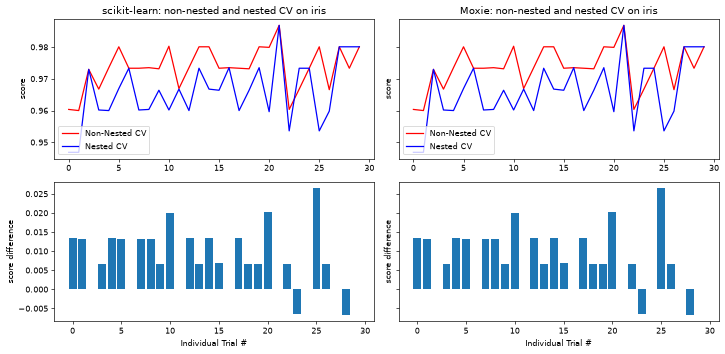

Moxie: Average difference of 0.007581 with std. dev. of 0.007833.


In [6]:
mx = nb.results["nested_cv"]
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey="row")
for col, (label, nn, ne) in enumerate([("scikit-learn", non_nested_scores, nested_scores),
                                       ("Moxie", mx["non_nested"], mx["nested"])]):
    ax = axes[0, col]
    ax.plot(nn, color="r", label="Non-Nested CV")
    ax.plot(ne, color="b", label="Nested CV")
    ax.set_title(label + ": non-nested and nested CV on iris")
    ax.set_ylabel("score")
    ax.legend(loc="lower left")
    axes[1, col].bar(range(NUM_TRIALS), nn - ne)
    axes[1, col].set_xlabel("Individual Trial #")
    axes[1, col].set_ylabel("score difference")
plt.tight_layout()
plt.show()
mx_diff = mx["non_nested"] - mx["nested"]
print("Moxie: Average difference of {:6f} with std. dev. of {:6f}.".format(mx_diff.mean(), mx_diff.std()))
moxie_nb.side_by_side(sklearn_non_nested=non_nested_scores[:10], moxie_non_nested=mx["non_nested"][:10],
                      sklearn_nested=nested_scores[:10], moxie_nested=mx["nested"][:10])

In [7]:
exact_reason = "accuracies are ratios of integer counts over identical folds and identical fitted SVCs"
nb.compare("non_nested best_score_", non_nested_scores, mx["non_nested"], rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("nested cross_val_score mean", nested_scores, mx["nested"], rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("nested per-fold scores", sk["nested_folds"], mx["nested_folds"], rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("best_index_", sk["best_index"], mx["best_index"], exact=True)
nb.compare("cv_results_ split*_test_score", sk["split_test_scores"], mx["split_test_scores"], rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("cv_results_ mean_test_score", sk["mean_test_score"], mx["mean_test_score"], rtol=0, atol=1e-15,
           reason="mean of four identical accuracies; summation order may differ in the last bit")
nb.compare("cv_results_ rank_test_score", sk["rank_test_score"], mx["rank_test_score"], exact=True)
nb.compare("mean_train_score (return_train_score)", first.cv_results_["mean_train_score"], mx["mean_train_score"],
           rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("best_params_ C", [p["C"] for p in [first.best_params_]], mx["best_C"][:1], exact=True)
nb.compare("best_params_ gamma", [first.best_params_["gamma"]], mx["best_gamma"][:1], exact=True)
nb.compare("refit predict", first.predict(X_iris), mx["refit_predict"], exact=True)
nb.compare("refit decision_function", first.decision_function(X_iris), mx["refit_decision"], rtol=1e-9, atol=1e-10,
           reason="same SMO working-set rules; dual coefficients may differ in the last bits from kernel-cache arithmetic order")
nb.compare("refit best_estimator_.support_", first.best_estimator_.support_, mx["refit_support"], exact=True)
nb.compare("RandomizedSearchCV sampled C", [p["C"] for p in random.cv_results_["params"]], mx["random_C"], exact=True)
nb.compare("RandomizedSearchCV sampled gamma", [p["gamma"] for p in random.cv_results_["params"]], mx["random_gamma"], exact=True)
nb.compare("RandomizedSearchCV mean_test_score", random.cv_results_["mean_test_score"], mx["random_mean_test_score"],
           rtol=0, atol=1e-15, reason=exact_reason)
nb.compare("RandomizedSearchCV best_index_", [random.best_index_], mx["random_best_index"], exact=True)
nb.note("cross_val_score(GridSearchCV)", "GAP",
        "Mojo 1.0 rejects function parameters typed with a struct that has a struct-level `where` clause; "
        "GridSearchCV/RandomizedSearchCV have one, so cross_validate/cross_val_score cannot take a search "
        "(compiler crash) and nested CV must be written as an explicit clone/fit/score loop")
nb.note("cv=KFold(...) object", "ADAPTED",
        "GridSearchCV.cv takes materialized folds; a splitter that must follow each outer training subset is "
        "expressed through the adapter's default_cv")
nb.note("cv_results_ dict", "ADAPTED",
        "typed SearchResults: split{k}_test_score -> scores.test_scores[c, k, metric], param_C -> parameter('C'); "
        "rank columns are Int64 instead of Int32")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
non_nested best_score_,PASS,"(30,)","(30,)",0,0,"rtol=0, atol=1e-15",,accuracies are ratios of integer counts over identical folds and identical fitted SVCs
nested cross_val_score mean,PASS,"(30,)","(30,)",0,0,"rtol=0, atol=1e-15",,accuracies are ratios of integer counts over identical folds and identical fitted SVCs
nested per-fold scores,PASS,"(120,)","(120,)",0,0,"rtol=0, atol=1e-15",,accuracies are ratios of integer counts over identical folds and identical fitted SVCs
best_index_,PASS,"(30,)","(30,)",,,exact,0 mismatches,
cv_results_ split*_test_score,PASS,"(720,)","(720,)",0,0,"rtol=0, atol=1e-15",,accuracies are ratios of integer counts over identical folds and identical fitted SVCs
cv_results_ mean_test_score,PASS,"(180,)","(180,)",0,0,"rtol=0, atol=1e-15",,mean of four identical accuracies; summation order may differ in the last bit
cv_results_ rank_test_score,PASS,"(180,)","(180,)",,,exact,0 mismatches,
mean_train_score (return_train_score),PASS,"(6,)","(6,)",0,0,"rtol=0, atol=1e-15",,accuracies are ratios of integer counts over identical folds and identical fitted SVCs
best_params_ C,PASS,"(1,)","(1,)",,,exact,0 mismatches,
best_params_ gamma,PASS,"(1,)","(1,)",,,exact,0 mismatches,
